# Data Collection and Preparation:
- ingesting the data in appropriate format (Unsere Jungs fragen: [1,2,3,4] -> [1,2] + [3], [2,3] + [4]) + fragen: was die anderen unter data ingestion verstehen? (Beide Datensätze mergen?)
- checking for missing or erroneous data
- cleaning your dataset

Dicuss our assumption
Was mit Datensätzen machen, die Prozesschritte nicht einhalten?

In [47]:
import pandas as pd
import ast

In [48]:
# Ingesting the data
data_weather = pd.read_csv("../data/weather_burbank_airport.csv")


data_charge = pd.read_csv("../data/charging_sessions.csv")

In [49]:
# Get a brief overview
data_weather.head(3)

,city,timestamp,temperature,cloud_cover,cloud_cover_description,pressure,windspeed,precipitation,felt_temperature
0,Burbank,2018-01-01 08:53:00,9.0,33.0,Fair,991.75,9.0,0.0,8.0
1,Burbank,2018-01-01 09:53:00,9.0,33.0,Fair,992.08,0.0,0.0,9.0
2,Burbank,2018-01-01 10:53:00,9.0,21.0,Haze,992.08,0.0,0.0,9.0


In [50]:
# Get a brief overview
data_charge.head(3)

,Unnamed: 0,id,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs
0,0,5e23b149f9af8b5fe4b973cf,2020-01-02 13:08:54+00:00,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,25.016,1_1_179_810_2020-01-02 13:08:53.870034,1,AG-3F30,1-1-179-810,America/Los_Angeles,194.0,"[{'WhPerMile': 250, 'kWhRequested': 25.0, 'mil..."
1,1,5e23b149f9af8b5fe4b973d0,2020-01-02 13:36:50+00:00,2020-01-02 22:38:21+00:00,2020-01-02 20:18:05+00:00,33.097,1_1_193_825_2020-01-02 13:36:49.599853,1,AG-1F01,1-1-193-825,America/Los_Angeles,4275.0,"[{'WhPerMile': 280, 'kWhRequested': 70.0, 'mil..."
2,2,5e23b149f9af8b5fe4b973d1,2020-01-02 13:56:35+00:00,2020-01-03 00:39:22+00:00,2020-01-02 16:35:06+00:00,6.521,1_1_193_829_2020-01-02 13:56:35.214993,1,AG-1F03,1-1-193-829,America/Los_Angeles,344.0,"[{'WhPerMile': 400, 'kWhRequested': 8.0, 'mile..."


In [51]:
data_charge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66450 entries, 0 to 66449
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        66450 non-null  int64  
 1   id                66450 non-null  object 
 2   connectionTime    66450 non-null  object 
 3   disconnectTime    66450 non-null  object 
 4   doneChargingTime  62362 non-null  object 
 5   kWhDelivered      66450 non-null  float64
 6   sessionID         66450 non-null  object 
 7   siteID            66450 non-null  int64  
 8   spaceID           66450 non-null  object 
 9   stationID         66450 non-null  object 
 10  timezone          66450 non-null  object 
 11  userID            49187 non-null  float64
 12  userInputs        49187 non-null  object 
dtypes: float64(2), int64(2), object(9)
memory usage: 6.6+ MB


In [52]:
# Get a brief overview
data_charge.describe()

,Unnamed: 0,kWhDelivered,siteID,userID
count,66450.000000,66450.000000,66450.000000,49187.000000
mean,4726.102062,11.787916,1.472656,1800.494582
std,3568.025394,10.314789,0.499256,2617.548614
min,0.000000,0.501000,1.000000,1.000000
25%,1845.000000,5.097000,1.000000,431.000000
50%,3960.000000,9.140000,1.000000,818.000000
75%,7027.000000,14.183000,2.000000,1805.000000
max,15291.000000,108.797242,2.000000,19923.000000


### Note: The max kWhDelivered seems to be suspect! The data of siteID looks good. Maybe there is a outlier in userID.

In [53]:
data_charge[data_charge["kWhDelivered"] > 80]

,Unnamed: 0,id,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs
18641,4338,610c829df9af8b0580e98730,2021-07-20 22:16:54+00:00,2021-07-21 15:18:03+00:00,2021-07-21 15:19:00+00:00,108.797242,1_1_193_829_2021-07-20 18:27:33.500144,1,AG-1F03,1-1-193-829,America/Los_Angeles,378.0,"[{'WhPerMile': 258, 'kWhRequested': 35.088, 'm..."
18643,4340,610c829df9af8b0580e98732,2021-07-20 22:16:56+00:00,2021-07-21 15:18:16+00:00,2021-07-21 15:19:13+00:00,89.362732,1_1_194_818_2021-07-20 13:54:47.875453,1,AG-1F14,1-1-194-818,America/Los_Angeles,481.0,"[{'WhPerMile': 360, 'kWhRequested': 86.4, 'mil..."


In [54]:
# NOTE: Maybe drop the  outlier from above!

In [55]:
# Get a brief overview
data_charge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66450 entries, 0 to 66449
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        66450 non-null  int64  
 1   id                66450 non-null  object 
 2   connectionTime    66450 non-null  object 
 3   disconnectTime    66450 non-null  object 
 4   doneChargingTime  62362 non-null  object 
 5   kWhDelivered      66450 non-null  float64
 6   sessionID         66450 non-null  object 
 7   siteID            66450 non-null  int64  
 8   spaceID           66450 non-null  object 
 9   stationID         66450 non-null  object 
 10  timezone          66450 non-null  object 
 11  userID            49187 non-null  float64
 12  userInputs        49187 non-null  object 
dtypes: float64(2), int64(2), object(9)
memory usage: 6.6+ MB


# Parse data

In [56]:
# Parse the datetime
data_charge["connectionTime"] = pd.to_datetime(data_charge["connectionTime"])
data_charge["disconnectTime"] = pd.to_datetime(data_charge["disconnectTime"])
data_charge["doneChargingTime"] = pd.to_datetime(data_charge["doneChargingTime"])

# data_charge = data_charge.set_index("connectionTime")

In [57]:
# Check the location
data_charge["timezone"].unique()

array(['America/Los_Angeles'], dtype=object)

=> Since time timezone is 'America/Los_Angeles' but the data description states that the data is in UTC, we have have to transform it.

In [58]:
# Change timezone

data_charge["connectionTime"] = data_charge["connectionTime"].dt.tz_convert("America/Los_Angeles")
data_charge["disconnectTime"] = data_charge["disconnectTime"].dt.tz_convert("America/Los_Angeles")
data_charge["doneChargingTime"] = data_charge["doneChargingTime"].dt.tz_convert(
    "America/Los_Angeles"
)

# Try to find missing or erroneous data

In [59]:
data_charge[data_charge["id"] == "5d2fbdd3f9af8b4d0dd0d54f"]

,Unnamed: 0,id,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs
5573,0,5d2fbdd3f9af8b4d0dd0d54f,2019-07-01 17:32:46-07:00,2019-07-01 19:34:56-07:00,2019-07-01 18:46:09-07:00,2.463,1_1_193_827_2019-07-02 00:32:45.820079,1,AG-1F02,1-1-193-827,America/Los_Angeles,1117.0,"[{'WhPerMile': 200, 'kWhRequested': 4.0, 'mile..."
65037,8675,5d2fbdd3f9af8b4d0dd0d54f,2019-07-01 17:32:46-07:00,2019-07-01 19:34:56-07:00,2019-07-01 18:46:09-07:00,2.463,1_1_193_827_2019-07-02 00:32:45.820079,1,AG-1F02,1-1-193-827,America/Los_Angeles,1117.0,"[{'WhPerMile': 200, 'kWhRequested': 4.0, 'mile..."


In [60]:
# Find and remove dupplicates
print(len(data_charge))
print(data_charge["id"].unique().__len__())
print(data_charge[data_charge["id"].duplicated()].__len__())
print(data_charge[data_charge["sessionID"].duplicated()].__len__())

data_charge[data_charge["id"].duplicated()][:3]

# drop them:
data_charge = data_charge.drop_duplicates(subset=["id"], keep="first")
print(len(data_charge))

66450
65037
1413
1413
65037


In [61]:
# Find null records
data_charge.isnull().sum()

Unnamed: 0              0
id                      0
connectionTime          0
disconnectTime          0
doneChargingTime     4087
kWhDelivered            0
sessionID               0
siteID                  0
spaceID                 0
stationID               0
timezone                0
userID              17215
userInputs          17215
dtype: int64

In [62]:
# Check if disconnect time == doneChargingTime
matching_records = data_charge[data_charge["doneChargingTime"] == data_charge["disconnectTime"]]
len(matching_records)

5

There seems to be very few records that have the same disconnect and done charging time

We assume that the 4087 records that have a NaN value in the "doneChargingTime" column are caused by the incident that the EV owner is disconnecting the charger before the EV is fully loaded. (TODO: Discuss this assumption)

Since we need the information about the end of charging time for future feature enginiering and doneChargingTime does not capture this information if the charger gets disconnected before full load, we create the feature "endChargingTime": 

In [63]:
# Add a column "endChargingTime" that holds the time when charging ended (doneChargingTime or disconnectTime if the doneChargingTime was null)
data_charge["endChargingTime"] = data_charge["doneChargingTime"].fillna(
    data_charge["disconnectTime"]
)
data_charge["endChargingTime"].isnull().sum()

0

In [64]:
# Add a column "chargingDurationMin" that covers information how long the cars took to charge (endChargingTime-connectionTime)
data_charge["chargingDurationMin"] = (
    data_charge["endChargingTime"] - data_charge["connectionTime"]
).dt.total_seconds() / 60

In [65]:
# Add a column "blockingDurationMin" that covers information how long the cars stayed on a slot without charging (disconnectTime-endChargingTime)
data_charge["blockingDurationMin"] = (
    data_charge["disconnectTime"] - data_charge["endChargingTime"]
).dt.total_seconds() / 60

In [66]:
# Check if the time of the process steps is continous
# Check if disconnectTime is larger or equal than doneChargingTime and this should be larger or equal than connection time
valid_records = data_charge[
    (data_charge["disconnectTime"] >= data_charge["doneChargingTime"])
    & (data_charge["doneChargingTime"] >= data_charge["connectionTime"])
]

valid_count = len(valid_records)
total_count = len(data_charge)

print(f"Amount valid records: {valid_count}")
print(f"Amount records: {total_count}")
print(f"Valid records ratio: {valid_count / total_count * 100:.2f}%")

invalid_records = data_charge[
    ~(
        (data_charge["disconnectTime"] >= data_charge["doneChargingTime"])
        & (data_charge["doneChargingTime"] >= data_charge["connectionTime"])
    )
]

Amount valid records: 56536
Amount records: 65037
Valid records ratio: 86.93%


TODO: Was mit diesen Datensätzen machen?

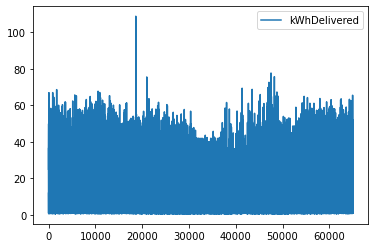

In [70]:
data_charge[["kWhDelivered"]].plot()

### Needed to remove possible outlier since one data point varies alot from the rest

In [75]:
data_charge.describe()

,Unnamed: 0,kWhDelivered,siteID,userID,chargingDurationMin,blockingDurationMin,chargeTimeJH,userInputs_parsed_len
count,65037.000000,65037.000000,65037.000000,47822.000000,65037.000000,65037.000000,60950,65037.000000
mean,4624.969310,11.734288,1.482925,1821.825457,216.077912,160.440178,0 days 03:31:28.491878589,0.948122
std,3538.755066,10.278928,0.499712,2647.909756,189.152645,236.783846,0 days 03:03:52.329226151,1.037380
min,0.000000,0.501000,1.000000,1.000000,-41.366667,-59.933333,-1 days +23:18:38,0.000000
25%,1806.000000,5.060000,1.000000,436.000000,95.150000,0.100000,0 days 01:37:03.250000,0.000000
50%,3859.000000,9.099000,1.000000,826.000000,167.333333,75.800000,0 days 02:45:33,1.000000
75%,6762.000000,14.127000,2.000000,1813.000000,291.366667,281.250000,0 days 04:43:31,1.000000
max,15291.000000,108.797242,2.000000,19923.000000,12000.950000,9367.283333,8 days 08:00:57,58.000000


Insight: Datapoints with negative charge and blockingDuration. Additionaly there also data with very high charge duration

In [ ]:
data_charge[data_charge["chargingDurationMin"] > 2880].__len__()

16

Discuss if these values need to be dropped for the others work.

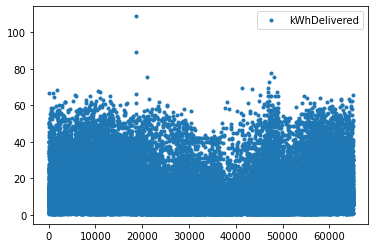

In [71]:
data_charge[["kWhDelivered"]].plot(style=".")

### Insight: Missing data

## Outlier analysis

In [72]:
data_charge.describe()

,Unnamed: 0,kWhDelivered,siteID,userID,chargingDurationMin,blockingDurationMin,chargeTimeJH
count,65037.000000,65037.000000,65037.000000,47822.000000,65037.000000,65037.000000,60950
mean,4624.969310,11.734288,1.482925,1821.825457,216.077912,160.440178,0 days 03:31:28.491878589
std,3538.755066,10.278928,0.499712,2647.909756,189.152645,236.783846,0 days 03:03:52.329226151
min,0.000000,0.501000,1.000000,1.000000,-41.366667,-59.933333,-1 days +23:18:38
25%,1806.000000,5.060000,1.000000,436.000000,95.150000,0.100000,0 days 01:37:03.250000
50%,3859.000000,9.099000,1.000000,826.000000,167.333333,75.800000,0 days 02:45:33
75%,6762.000000,14.127000,2.000000,1813.000000,291.366667,281.250000,0 days 04:43:31
max,15291.000000,108.797242,2.000000,19923.000000,12000.950000,9367.283333,8 days 08:00:57


### 


Explore now the weather dataset

In [83]:
data_weather.head(3)

,city,timestamp,temperature,cloud_cover,cloud_cover_description,pressure,windspeed,precipitation,felt_temperature
0,Burbank,2018-01-01 08:53:00,9.0,33.0,Fair,991.75,9.0,0.0,8.0
1,Burbank,2018-01-01 09:53:00,9.0,33.0,Fair,992.08,0.0,0.0,9.0
2,Burbank,2018-01-01 10:53:00,9.0,21.0,Haze,992.08,0.0,0.0,9.0


In [84]:
data_weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29244 entries, 0 to 29243
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   city                     29244 non-null  object 
 1   timestamp                29244 non-null  object 
 2   temperature              29219 non-null  float64
 3   cloud_cover              29224 non-null  float64
 4   cloud_cover_description  29224 non-null  object 
 5   pressure                 29236 non-null  float64
 6   windspeed                29158 non-null  float64
 7   precipitation            29244 non-null  float64
 8   felt_temperature         29218 non-null  float64
dtypes: float64(6), object(3)
memory usage: 2.0+ MB


In [85]:
data_weather.describe()

,temperature,cloud_cover,pressure,windspeed,precipitation,felt_temperature
count,29219.000000,29224.000000,29236.000000,29158.000000,29244.000000,29218.000000
mean,17.885622,30.107993,986.879400,8.566568,0.059360,17.731433
std,6.454604,5.400388,3.607065,6.699889,0.471682,6.321100
min,2.000000,4.000000,971.000000,0.000000,0.000000,0.000000
25%,13.000000,26.000000,984.500000,6.000000,0.000000,13.000000
50%,17.000000,33.000000,986.480000,7.000000,0.000000,17.000000
75%,22.000000,34.000000,989.110000,13.000000,0.000000,22.000000
max,46.000000,47.000000,999.650000,57.000000,18.540000,42.000000


Note: Data looks good. Discuss if we should prepare the time stamp again.

 Temporal Patterns and Seasonality: Demonstrate how the number of charging events varies during
 the day, the week, and between seasons. What patterns can you observe, and how do you explain
 them?

In [88]:
data_charge.columns

Index(['Unnamed: 0', 'id', 'connectionTime', 'disconnectTime',
       'doneChargingTime', 'kWhDelivered', 'sessionID', 'siteID', 'spaceID',
       'stationID', 'timezone', 'userID', 'userInputs', 'endChargingTime',
       'chargingDurationMin', 'blockingDurationMin', 'chargeTimeJH',
       'userInputs_parsed', 'userInputs_parsed_len'],
      dtype='object')

In [93]:
data_charge.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 65037 entries, 0 to 65036
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype                              
---  ------                 --------------  -----                              
 0   Unnamed: 0             65037 non-null  int64                              
 1   id                     65037 non-null  object                             
 2   connectionTime         65037 non-null  datetime64[ns, America/Los_Angeles]
 3   disconnectTime         65037 non-null  datetime64[ns, America/Los_Angeles]
 4   doneChargingTime       60950 non-null  datetime64[ns, America/Los_Angeles]
 5   kWhDelivered           65037 non-null  float64                            
 6   sessionID              65037 non-null  object                             
 7   siteID                 65037 non-null  int64                              
 8   spaceID                65037 non-null  object                             
 9   statio

In [97]:
data_charge["connectionTime"] = pd.to_datetime(data_charge["connectionTime"])

In [100]:
data_charge["connectionTime"].groupby("d")

KeyError: 'd'

# Backup 

In [73]:
# Insights and parsing of user inputs


data_charge["userInputs_parsed"] = data_charge["userInputs"].apply(str)
data_charge["userInputs_parsed"] = data_charge.userInputs.apply(
    lambda x: ast.literal_eval(x) if type(x) == str else []
)
data_charge["userInputs_parsed"].iloc[5]
data_charge["userInputs_parsed_len"] = data_charge["userInputs_parsed"].apply(len)

data_charge["userInputs_parsed_len"].value_counts()
data_charge[data_charge["userInputs_parsed_len"] == 3]["userInputs_parsed"].iloc[0]

[{'WhPerMile': 400,
  'kWhRequested': 8.0,
  'milesRequested': 20,
  'minutesAvailable': 316,
  'modifiedAt': 'Thu, 02 Jan 2020 15:23:27 GMT',
  'paymentRequired': True,
  'requestedDeparture': 'Thu, 02 Jan 2020 20:39:27 GMT',
  'userID': 3399},
 {'WhPerMile': 400,
  'kWhRequested': 8.0,
  'milesRequested': 20,
  'minutesAvailable': 177,
  'modifiedAt': 'Thu, 02 Jan 2020 18:04:40 GMT',
  'paymentRequired': True,
  'requestedDeparture': 'Thu, 02 Jan 2020 18:20:27 GMT',
  'userID': 3399},
 {'WhPerMile': 400,
  'kWhRequested': 8.0,
  'milesRequested': 20,
  'minutesAvailable': 191,
  'modifiedAt': 'Thu, 02 Jan 2020 18:05:13 GMT',
  'paymentRequired': True,
  'requestedDeparture': 'Thu, 02 Jan 2020 18:34:27 GMT',
  'userID': 3399}]